# Blok 10: Praktyczna analiza danych z wykorzystaniem Pythona

Ten notebook zawiera zadania bez rozwiązań. Uzupełniaj miejsca oznaczone `TODO`.

**Zasada bloku:** najpierw pytanie biznesowe → potem wykres → potem 1 zdanie wniosku.


## Opis datasetów (skrót)

### 1) air_quality.csv (główny)
Pomiary godzinowe jakości powietrza dla wielu stacji.

Kolumny:
- `date_time` (str → datetime): czas pomiaru
- `station` (kategoria): nazwa stacji
- Zanieczyszczenia (float): `PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`
- Pogoda/warunki (float/kategoria): `TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`, `wd`

### 2) bank.csv
Dane kampanii bankowej, target `deposit` (yes/no).

Kolumny (wybrane):
- numeryczne: `age`, `balance`, `duration`, `campaign`, `pdays`, `previous`
- kategoryczne: `job`, `education`, `housing`, `loan`, `poutcome`, `month`, `deposit`

### 3) AI_Poland_Jobs_2022_06_10.csv (rozgrzewka)
Ogłoszenia o pracę.

Kolumny:
- `Title`, `Senior` (bool), `Company`, `Location`
- `Salary_Min`, `Salary_Max` (int)


In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

# ustawienia wykresów (możesz zmienić pod siebie)
plt.rcParams["figure.figsize"] = (10, 4)
sns.set_theme(style="whitegrid")

print("Imports OK")


Imports OK


In [2]:
PATH_AIR  = "data/air_quality.csv"
PATH_BANK = "data/bank.csv"
PATH_JOBS = "data/AI_Poland_Jobs_2022_06_10.csv"

In [3]:
df_air = pd.read_csv(PATH_AIR)
df_bank = pd.read_csv(PATH_BANK)
df_jobs = pd.read_csv(PATH_JOBS)

In [4]:
# Check data loop
for name, df in [('air', df_air), ('bank', df_bank), ('jobs', df_jobs)]:
    print(name, df.shape)
    display(df.head())

air (95685, 14)


,date_time,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2013-03-01 01:00:00,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,2013-03-01 05:00:00,4.0,4.0,9.0,25.0,300.0,78.0,-2.4,1027.5,-21.3,0.0,NW,2.4,Dongsi
3,2013-03-01 06:00:00,5.0,5.0,10.0,29.0,400.0,67.0,-2.5,1028.2,-20.4,0.0,NW,2.2,Dongsi
4,2013-03-01 07:00:00,3.0,6.0,12.0,40.0,400.0,52.0,-1.4,1029.5,-20.4,0.0,NNW,3.0,Dongsi


bank (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


jobs (52, 7)


,Id,Title,Senior,Company,Location,Salary_Min,Salary_Max
0,1.0,AI Developer / Data Scientist,False,Algomine,Remote,22652,25997
1,2.0,Data Scientist,False,Addepto,Remote,10394,16117
2,3.0,Machine Learning Engineer -Data Scientis,False,OpenX,Remote,27948,32405
3,4.0,Senior Data Scientist,True,hubQuest,Remote,25800,31584
4,5.0,Senior AI Engineer,True,Link Group,Remote,18433,22317


## Rozgrzewka (Dataset C: AI jobs) — 4 szybkie zadania

Cel: rozgrzać Pandasa i zrobić 2–3 proste wykresy.


### Zadanie 1 (5–7 min)
**Biznes:** Ile ogłoszeń mamy w podziale na `Senior`?

**Technicznie:** `value_counts`, udział procentowy.

**TODO:** policz i pokaż tabelę z liczbą i %.


In [5]:
counts = df_jobs['Senior'].value_counts(dropna=False)
share = (df_jobs['Senior'].value_counts(normalize=True, dropna=False) * 100).round(2)
result = pd.DataFrame({'Count' : counts, 'Share_pct' : share})
display(result)

,Count,Share_pct
Senior,,
False,41,78.85
True,11,21.15


### Zadanie 2 (7–10 min)
**Biznes:** Top 10 lokalizacji po liczbie ofert.

**Technicznie:** `groupby`/`value_counts`, sortowanie.

**TODO:** zrób tabelę top 10.

In [6]:
df_jobs.loc[df_jobs['Location'].str.contains('Warszawa'), 'Location'] = 'Warszawa'
top_loc = df_jobs['Location'].value_counts().head(10)
top_loc


Location
Remote           41
Warszawa          5
Warsaw, POL       2
Kraków, POL       1
Gdańsk, POL       1
Otwock, POL       1
Katowice, POL     1
Name: count, dtype: int64

### Zadanie 3 (10–12 min)
**Biznes:** Jak wyglądają widełki płac? (Salary_Min vs Salary_Max)

**Technicznie:** nowa kolumna `salary_mid` (średnia z widełek), histogram.

**TODO:** dodaj `salary_mid` i narysuj histogram (Matplotlib lub Seaborn).


count       52.000000
mean     21365.557692
std       6172.927622
min      11698.000000
25%      16159.125000
50%      19601.000000
75%      27957.500000
max      31178.000000
Name: Salary_Mid, dtype: float64

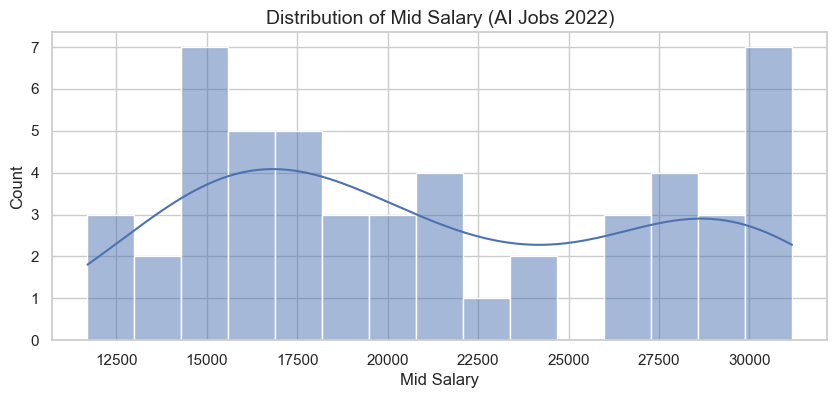

In [7]:
df_jobs["Salary_Mid"] = df_jobs[["Salary_Min", "Salary_Max"]].mean(axis=1)

sns.histplot(data=df_jobs[df_jobs["Salary_Mid"].notnull()], x="Salary_Mid", bins=15, kde=True)
plt.title("Distribution of Mid Salary (AI Jobs 2022)", fontsize=14)
plt.xlabel("Mid Salary", fontsize=12)
plt.ylabel("Count", fontsize=12)

df_jobs["Salary_Mid"].describe()

### Zadanie 4 (10–12 min)
**Biznes:** Czy oferty `Senior=True` mają wyższe widełki?

**Technicznie:** boxplot/violin, porównanie rozkładów.

**TODO:** wykres `salary_mid` w grupach `Senior` + 1 zdanie wniosku w markdown.


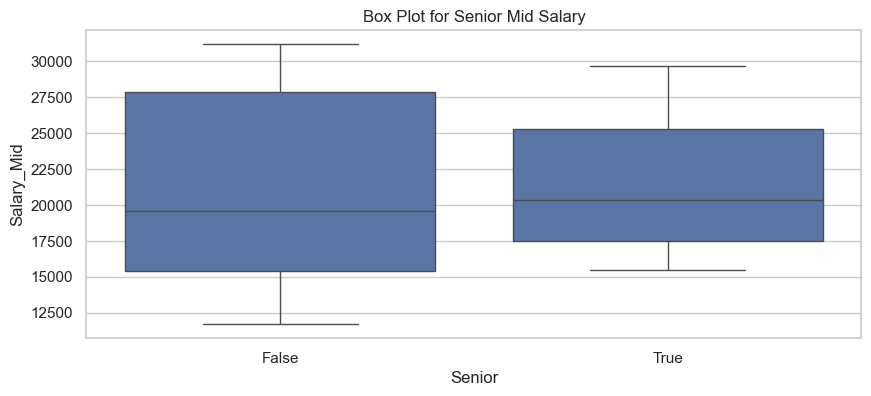

,count,mean,std,min,25%,50%,75%,max
Senior,,,,,,,,
False,41.0,21311.609756,6464.720214,11698.0,15371.0,19587.5,27886.0,31178.0
True,11.0,21566.636364,5206.615259,15497.0,17482.5,20375.0,25279.0,29680.0


In [8]:
sns.boxplot(data=df_jobs, x="Senior", y="Salary_Mid")
plt.title("Box Plot for Senior Mid Salary")
plt.show()

df_jobs[['Salary_Mid', 'Senior']].groupby('Senior')['Salary_Mid'].describe()


> Rozstrzał jest mniejszy dla Seniora pod względem zarobków

## Część główna (Dataset A: air_quality) — EDA + Matplotlib/Seaborn

Cel: zbudować zestaw wykresów, które później wejdą do raportu.


### Zadanie 5 (8–10 min)
**Biznes:** Upewnij się, że dane są poprawnie wczytane.

**Technicznie:** `info()`, `isna().sum()`, podstawowe statystyki.

**TODO:** zrób szybki „sanity check” i zapisz 2 obserwacje.


In [9]:
df_air.info()
display(df_air.isna().sum().sort_values(ascending=False).head(10))
df_air.describe().T.head(10)


<class 'pandas.DataFrame'>
RangeIndex: 95685 entries, 0 to 95684
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date_time  95685 non-null  str    
 1   PM2.5      95685 non-null  float64
 2   PM10       95685 non-null  float64
 3   SO2        95685 non-null  float64
 4   NO2        95685 non-null  float64
 5   CO         95685 non-null  float64
 6   O3         95685 non-null  float64
 7   TEMP       95685 non-null  float64
 8   PRES       95685 non-null  float64
 9   DEWP       95685 non-null  float64
 10  RAIN       95685 non-null  float64
 11  wd         95685 non-null  str    
 12  WSPM       95685 non-null  float64
 13  station    95685 non-null  str    
dtypes: float64(11), str(3)
memory usage: 10.2 MB


date_time    0
PM2.5        0
PM10         0
SO2          0
NO2          0
CO           0
O3           0
TEMP         0
PRES         0
DEWP         0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
PM2.5,95685.0,83.477884,82.678134,2.0000,23.0,59.0,116.0,821.0
PM10,95685.0,111.899959,94.775897,2.0000,41.0,90.0,154.0,994.0
SO2,95685.0,15.369771,20.381452,1.0000,3.0,7.0,20.0,500.0
NO2,95685.0,54.178310,34.244600,2.0000,27.0,48.0,74.0,271.0
CO,95685.0,1313.024142,1187.100019,100.0000,600.0,900.0,1600.0,10000.0
O3,95685.0,56.786295,57.899402,0.4284,9.0,43.0,82.0,1071.0
TEMP,95685.0,13.729446,11.320713,-16.8000,3.5,14.6,23.4,41.6
PRES,95685.0,1011.397848,10.287210,984.0000,1003.0,1011.0,1019.6,1042.0
DEWP,95685.0,2.473027,13.717762,-35.3000,-8.7,3.0,15.0,28.8
RAIN,95685.0,0.064496,0.819959,0.0000,0.0,0.0,0.0,46.4


> TODO (obserwacje): 2–3 bullet pointy: gdzie są braki? czy są podejrzane wartości?


### Zadanie 6 (10–12 min)
**Biznes:** Analiza w czasie wymaga datetime.

**Technicznie:** `pd.to_datetime`, sortowanie.

**TODO:** skonwertuj `date_time` do datetime, posortuj dane rosnąco.


In [10]:
df_air["date_time"] = pd.to_datetime(df_air["date_time"])

In [11]:
df_air = df_air.sort_values(['station', 'date_time']).reset_index(drop=True)
df_air[["station", "date_time"]].head()

,station,date_time
0,Dongsi,2013-03-01 00:00:00
1,Dongsi,2013-03-01 01:00:00
2,Dongsi,2013-03-01 05:00:00
3,Dongsi,2013-03-01 06:00:00
4,Dongsi,2013-03-01 07:00:00


### Zadanie 7 (10–12 min)
**Biznes:** Jaki jest zakres czasu danych i ile jest stacji?

**Technicznie:** min/max daty, `nunique`.

**TODO:** wypisz zakres dat + liczbę stacji + listę stacji.


In [12]:
start = df_air['date_time'].min()
end = df_air['date_time'].max()
n_stations = df_air['station'].nunique()
stations = df_air['station'].unique().tolist()

for name, x in zip(["start", "end", "n_stations", "stations"], [start, end, n_stations, stations]):
    print(name, ":", x)

df_air.head()

start : 2013-03-01 00:00:00
end : 2017-02-28 23:00:00
n_stations : 3
stations : ['Dongsi', 'Gucheng', 'Tiantan']


,date_time,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013-03-01 00:00:00,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2013-03-01 01:00:00,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,2013-03-01 05:00:00,4.0,4.0,9.0,25.0,300.0,78.0,-2.4,1027.5,-21.3,0.0,NW,2.4,Dongsi
3,2013-03-01 06:00:00,5.0,5.0,10.0,29.0,400.0,67.0,-2.5,1028.2,-20.4,0.0,NW,2.2,Dongsi
4,2013-03-01 07:00:00,3.0,6.0,12.0,40.0,400.0,52.0,-1.4,1029.5,-20.4,0.0,NNW,3.0,Dongsi


### Zadanie 8 (12–15 min)
**Biznes:** Jak wygląda rozkład PM2.5 (całość) i czy są outliery?

**Technicznie:** histogram + linia KDE, kwantyle (p95/p99).

**TODO:** narysuj histogram + policz p95 i p99.


249.0 376.0


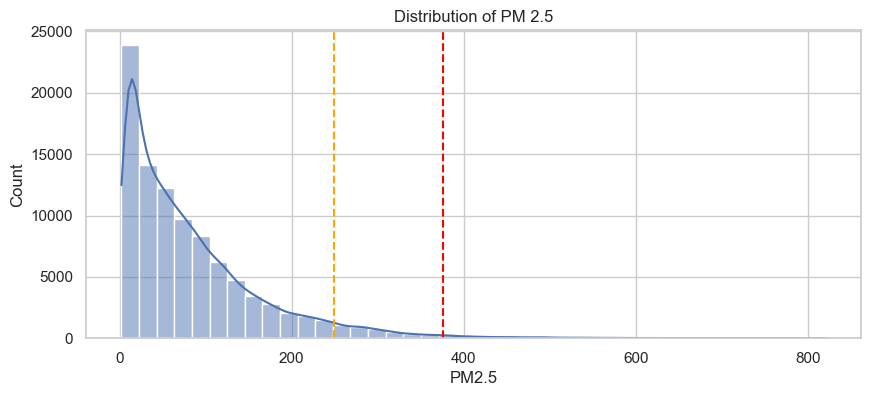

In [13]:
sns.histplot(data=df_air['PM2.5'], bins=40, kde=True)
plt.title("Distribution of PM 2.5")
p95 = df_air["PM2.5"].quantile(0.95)
p99 = df_air["PM2.5"].quantile(0.99)
print(p95, p99)

plt.axvline(p95, color="orange", linestyle="--", label=f"p95 = {p95:.0f}")
plt.axvline(p99, color="red", linestyle="--", label=f"p99 = {p99:.0f}")

### Zadanie 9 (10–12 min)
**Biznes:** Które stacje mają najwyższe typowe PM2.5?

**Technicznie:** boxplot PM2.5 per station albo barplot mediany.

**TODO:** zrób wykres porównawczy stacji (posortuj!).


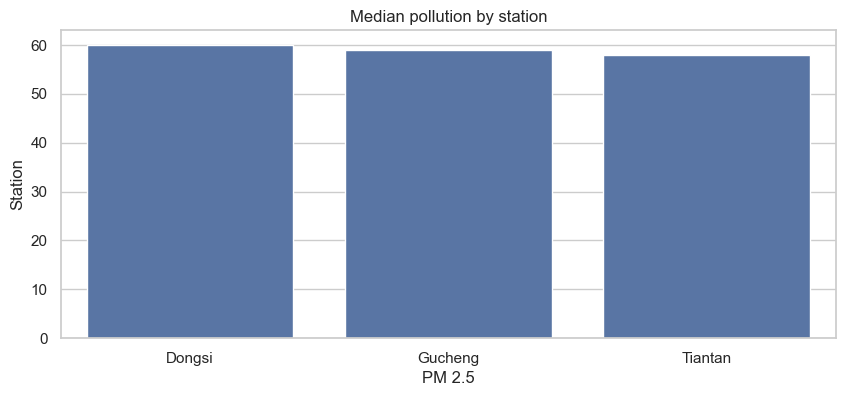

In [14]:
med = df_air.groupby("station")["PM2.5"].median().sort_values(ascending=False)
sns.barplot(x=med.index, y=med.values)
plt.title("Median pollution by station")
plt.xlabel("PM 2.5")
plt.ylabel("Station")
plt.show()


### Zadanie 10 (12–15 min)
**Biznes:** Trend w czasie bywa zaszumiony — zrób agregację dzienną.

**Technicznie:** `dt.date`/`dt.to_period`, `groupby`, średnia/mediana.

**TODO:** policz dzienną średnią PM2.5 dla całego miasta (wszystkie stacje razem).


In [15]:
df_air["date"] = pd.to_datetime(df_air["date_time"]).dt.date
df_daily = df_air.groupby('date', as_index=False).agg({'PM2.5':'mean'})
df_daily.head()

,date,PM2.5
0,2013-03-01,8.326531
1,2013-03-02,34.573529
2,2013-03-03,92.521739
3,2013-03-04,25.491525
4,2013-03-05,142.773585


### Zadanie 11 (10–12 min)
**Biznes:** Pokaż trend PM2.5 (dzienny) jako linię.

**Technicznie:** Matplotlib line plot, opisy osi.

**TODO:** narysuj wykres linii dla `df_daily`.


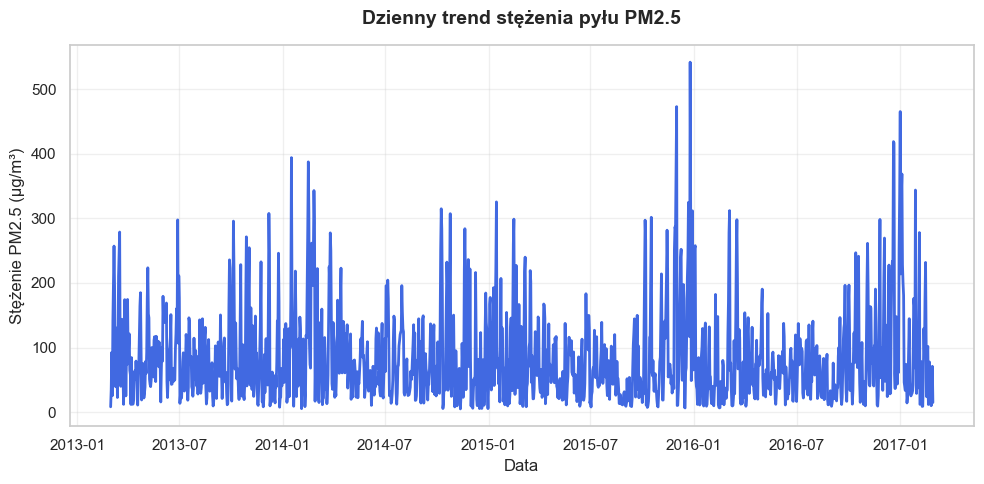

In [16]:
fig, ax = plt.subplots(figsize=(10, 5)) # Dodano figsize dla lepszej czytelności

ax.plot(df_daily['date'], df_daily['PM2.5'], color='royalblue', linewidth=2)

ax.set_title('Dzienny trend stężenia pyłu PM2.5', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Data', fontsize=12)
ax.set_ylabel('Stężenie PM2.5 (µg/m³)', fontsize=12)

ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### Zadanie 12 (12–15 min)
**Biznes:** Zrób wygładzenie rolling mean (np. 7 dni).

**Technicznie:** `rolling(window=7).mean()`.

**TODO:** dodaj kolumnę `pm25_roll7` i pokaż na wykresie razem z linią surową.


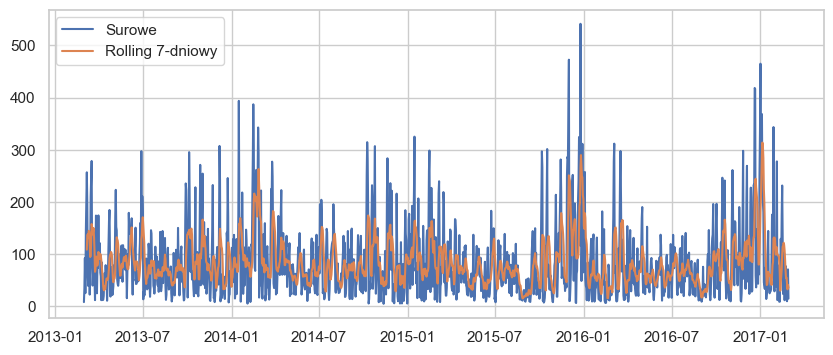

In [17]:
df_daily["pm25_roll7"] = df_daily["PM2.5"].rolling(window=7).mean()
plt.plot(df_daily['date'], df_daily['PM2.5'], label='Surowe')  # surowe
plt.plot(df_daily['date'], df_daily['pm25_roll7'], label='Rolling 7-dniowy')  # rolling
plt.legend()
plt.show()

### Zadanie 13 (12–15 min)
**Biznes:** Sezonowość: jak PM2.5 różni się między miesiącami?

**Technicznie:** wydobądź `month`, barplot mediany miesięcznej.

**TODO:** zrób wykres (miesiąc 1–12) i opisz wniosek.


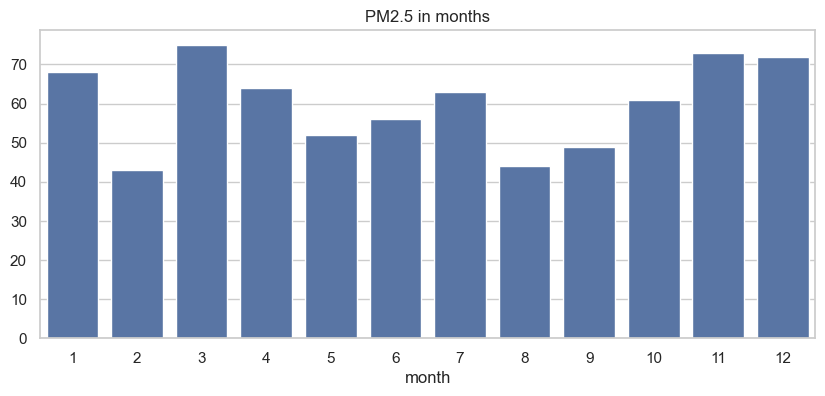

In [18]:
df_air["month"] = df_air["date_time"].dt.month
m = df_air.groupby("month")["PM2.5"].median().reindex(range(1,13))
sns.barplot(x=m.index, y=m.values)
plt.title("PM2.5 in months")
plt.show()

> Najmniej zanieczyszczeń w lutym, sierpniu i wrześniu, najwięcej w marcu (?), listopadzie i grudniu

### Zadanie 14 (12–15 min)
**Biznes:** Godzinowy wzorzec (czy w nocy jest gorzej?).

**Technicznie:** `hour`, pivot (hour × month) albo hour-only.

**TODO:** policz medianę PM2.5 po godzinie (0–23) i narysuj linię.


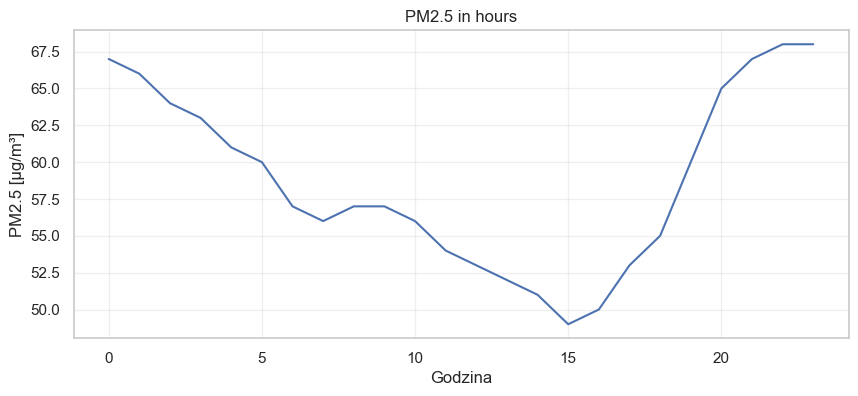

In [19]:
df_air["hour"] = df_air["date_time"].dt.hour
h = df_air.groupby("hour")["PM2.5"].median().reindex(range(24))
plt.plot(h.index, h.values)
plt.title("PM2.5 in hours")
plt.xlabel("Godzina")
plt.ylabel("PM2.5 [µg/m³]")
plt.grid(True, alpha=0.3)
plt.show()

### Zadanie 15 (15–18 min)
**Biznes:** Korelacje: które zmienne pogodowe mają związek z PM2.5?

**Technicznie:** korelacja na numerycznych kolumnach + heatmap.

**TODO:** policz macierz korelacji i narysuj heatmap.


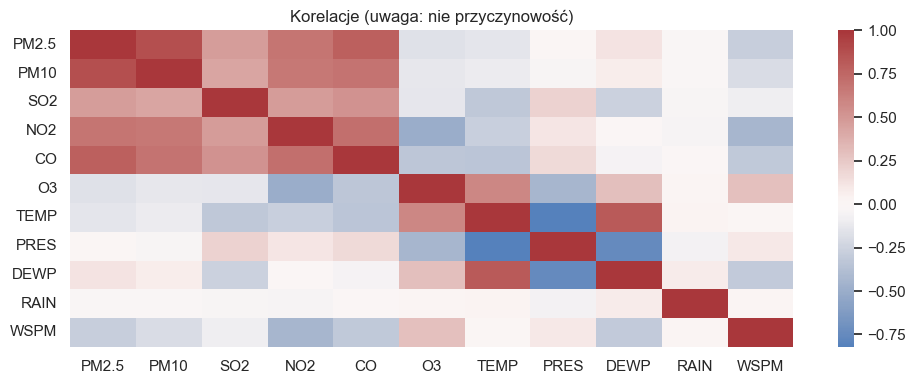

In [20]:
num_cols = ["PM2.5","PM10","SO2","NO2","CO","O3","TEMP","PRES","DEWP","RAIN","WSPM"]
corr = df_air[num_cols].corr()
sns.heatmap(corr, annot=False, cmap="vlag", center=0)
plt.title("Korelacje (uwaga: nie przyczynowość)")
plt.tight_layout()
plt.show()


### Zadanie 16 (12–15 min)
**Biznes:** Sprawdź relację `TEMP` vs `PM2.5`.

**Technicznie:** scatter + ewentualnie `sns.regplot` (na próbie!).

**TODO:** wylosuj próbkę (np. 5000 wierszy) i narysuj scatter.


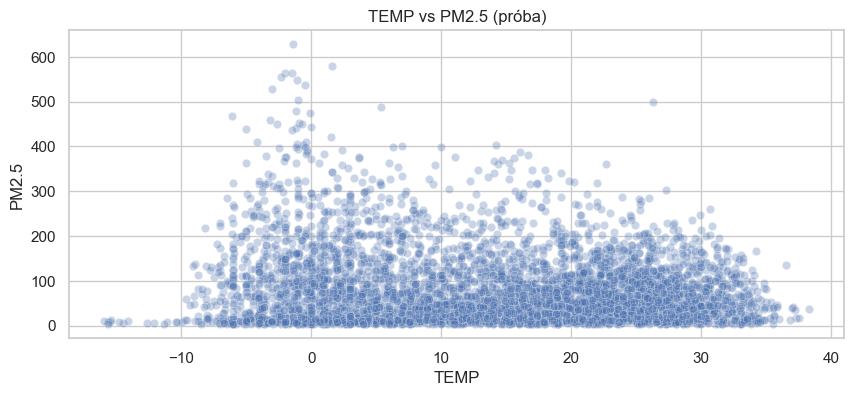

In [21]:
df_sample = df_air.sample(n=5000, random_state=42)
sns.scatterplot(data=df_sample, x="TEMP", y="PM2.5", alpha=0.3)
plt.title("TEMP vs PM2.5 (próba)")
plt.show()

### Zadanie 17 (15–20 min)
**Biznes:** Ranking stacji: które mają najwyższe PM2.5 w zimie?

**Technicznie:** filtr miesiące (12,1,2), agregacja per station, sort.

**TODO:** policz medianę PM2.5 w zimie per `station` i narysuj top 3.


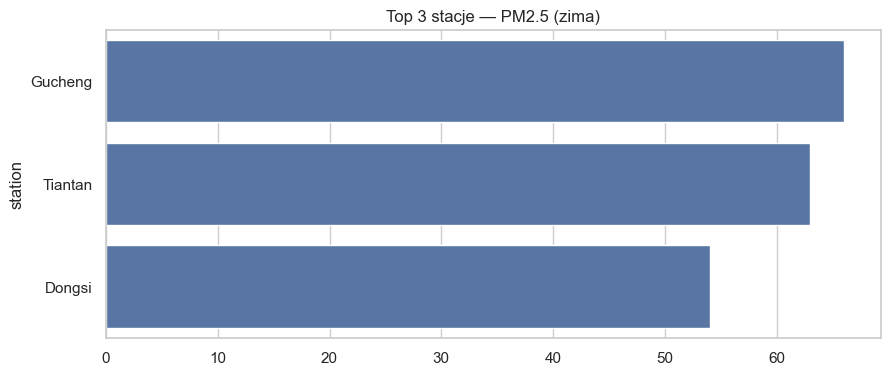

In [22]:
winter = df_air[df_air["month"].isin([12,1,2])].copy()
rank = winter.groupby("station")["PM2.5"].median().sort_values(ascending=False)
top3 = rank.head(3)
sns.barplot(x=top3.values, y=top3.index)
plt.title("Top 3 stacje — PM2.5 (zima)")
plt.show()


### Zadanie 18 (15–20 min)
**Biznes:** Porównaj dwie stacje w czasie (np. najlepszą i najgorszą z rankingu).

**Technicznie:** filtr 2 stacje, agregacja dzienna, wykres 2 linii.

**TODO:** wybierz 2 stacje i zrób porównanie trendu dziennego.


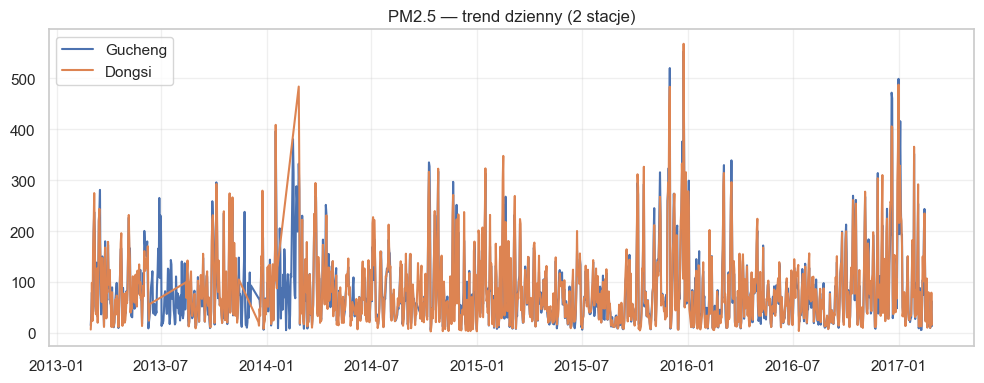

In [23]:
s1, s2 = top3.index[0], top3.index[-1]
df2 = df_air[df_air["station"].isin([s1, s2])].copy()
df2["date"] = df2["date_time"].dt.date
df2_daily = df2.groupby(["date","station"])["PM2.5"].mean().reset_index()

fig, ax = plt.subplots()
for st in [s1, s2]:
    tmp = df2_daily[df2_daily["station"] == st]
    ax.plot(tmp["date"], tmp["PM2.5"], label=st)

ax.set_title("PM2.5 — trend dzienny (2 stacje)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Plotly (Dataset A) — interaktywność + eksport do HTML

Cel: przygotować 2–4 interaktywne wykresy, które można wysłać jako pliki `.html`.


### Zadanie 19 (10–12 min)
**Biznes:** Interaktywny trend dzienny PM2.5 z możliwością hover.

**Technicznie:** `px.line`, zapis `write_html`.

**TODO:** użyj `df_daily` (z Zad. 10) i zapisz wykres jako `plot_pm25_daily.html`.


In [24]:
fig = px.line(df_daily, x="date", y="PM2.5", title="PM2.5 — średnia dzienna (all stations)")
fig.update_layout(xaxis_title='Data', yaxis_title='PM 2.5 [ug/m3]')
fig.write_html("plot_pm25_daily.html")
fig.show()


### Zadanie 20 (12–15 min)
**Biznes:** Interaktywny trend SO2 per stacja (ale tylko top N, żeby nie było chaosu).

**Technicznie:** wybór top 3 stacji po medianie, agregacja dzienna, `px.line(color='station')`.

**TODO:** przygotuj top 3, zbuduj `df_top_daily` i wykres.


In [25]:
df_daily_so2 = df_air.groupby(['date', 'station'], as_index=False)['SO2'].median()
fig = px.line(df_daily_so2, x="date", y="SO2", color="station", title="Zanieczyszczenie SO2 - trend dzienny")
fig.write_html("plot_SO2_top3_stations.html")
fig.update_layout(xaxis_title='Data', yaxis_title='Zanieczyszczenie SO2')
fig.show()


### Zadanie 21 (10–12 min)
**Biznes:** Porównanie rozkładów PM2.5 między stacjami (interaktywnie).

**Technicznie:** `px.box`.

**TODO:** zrób boxplot dla top 3 stacji i zapisz do HTML.


In [26]:
df_top3 = df_air[df_air["station"].isin(top3.index)].copy()
fig = px.box(df_top3, x="station", y="PM2.5", points=False, title="PM2.5 — rozkład (Top 3 stacji)")
fig.update_layout(xaxis_title="Stacja", yaxis_title="PM2.5 [µg/m³]")
fig.write_html("plot_pm25_box_top3.html")
fig.show()


### Zadanie 22 (12–15 min)
**Biznes:** Zależność `TEMP` vs `PM2.5` z kolorowaniem po porze roku.

**Technicznie:** dodaj `season` (zima/wiosna/lato/jesień), `px.scatter`.

**TODO:** utwórz `season` i zrób scatter + export HTML.


In [27]:
def month_to_season(m):
    if m in (12, 1, 2):
        return "zima"
    elif m in (3, 4, 5):
        return "wiosna"
    elif m in (6, 7, 8):
        return "lato"
    else:
        return "jesień"

df_air["season"] = df_air["month"].apply(month_to_season)
df_sample = df_air.sample(n=8000, random_state=42)

fig = px.scatter(
    df_sample, x="TEMP", y="PM2.5", color="season",
    opacity=0.4,
    category_orders={"season": ["zima", "wiosna", "lato", "jesień"]},
    hover_data=["date_time", "station"],
    title="TEMP vs PM2.5 (kolor: sezon, próba 8000)",
    labels={"TEMP": "TEMP [°C]", "PM2.5": "PM2.5 [µg/m³]", "season": "sezon"},
)
fig.update_traces(marker_size=5)
fig.write_html("plot_temp_vs_pm25_season.html")
fig.show()

### Zadanie 23 (10–12 min)
**Biznes:** Wykres udziałów braków danych per kolumna (żeby umieścić w raporcie).

**Technicznie:** policz % braków i zrób `px.bar`.

**TODO:** przygotuj `missing_pct` i wykres.


In [28]:
# Brak NaN

# missing_pct = (df_air.isna().mean() * 100).sort_values(ascending=False)
# miss_df = missing_pct.reset_index()
# miss_df.columns = ["column", "missing_pct"]
# fig = px.bar(miss_df, x="missing_pct", y="column", orientation="h",
#              title="Braki danych [%] — air_quality")
# fig.write_html("plot_missing_air_quality.html")
# fig.show()


### Zadanie 24 (12–15 min)
**Biznes:** Zrób mini-dashboard (1 strona) — 2 wykresy w jednym HTML.

**Technicznie:** `plotly.subplots.make_subplots` + `go.Scatter`.

**TODO:** połącz np. trend dzienny + rozkład (histogram) w jeden plik HTML.


In [29]:
# TODO
from plotly.subplots import make_subplots
df_daily_o3 = df_air.groupby(['date', 'station'], as_index=False)['O3'].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("Trend dzienny", "Rozkład O3"))

fig.add_trace(go.Scatter(x=df_daily_o3['date'], y=df_daily_o3['O3'], mode='lines', name='O3 Trend'), row=1, col=1)
fig.add_trace(go.Histogram(x=df_daily_o3['O3'], name='O3 Histogram', nbinsx=50), row=1, col=2)

fig.update_layout(title_text="Air Quality — mini-dashboard", showlegend=False)
fig.update_xaxes(title_text="Data", row=1, col=1)
fig.update_yaxes(title_text="Stężenie O3 [µg/m³]", row=1, col=1)
fig.update_xaxes(title_text="Stężenie O3 [µg/m³]", row=1, col=2)
fig.update_yaxes(title_text="Liczba obserwacji", row=1, col=2)
fig.write_html("dashboard_air_quality.html")
fig.show()


## Dataset B: bank — wizualizacje pod decyzję kampanijną

Cel: pokazać różnice między klientami, którzy założyli lokatę vs nie.


### Zadanie 25 (10–12 min)
**Biznes:** Jaki jest overall conversion rate (`deposit=yes`)?

**Technicznie:** `value_counts(normalize=True)` + prosty barplot.

**TODO:** policz conversion i narysuj wykres udziałów.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


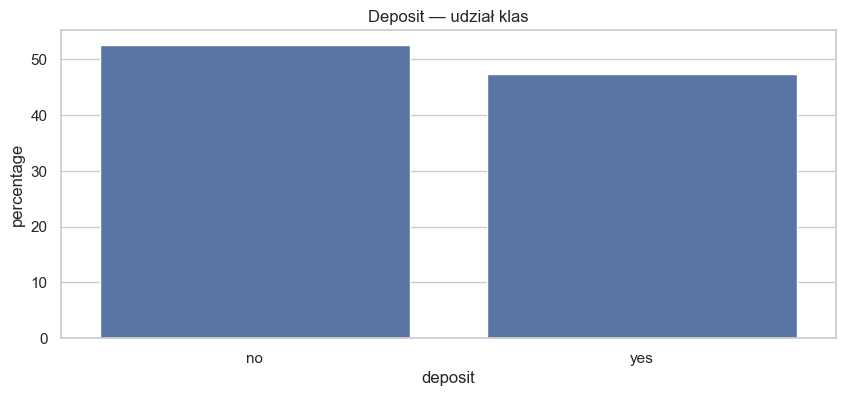

In [40]:
display(df_bank)
conv = df_bank['deposit'].value_counts(normalize=True) * 100
conv_df = conv.to_frame().reset_index().rename(columns={'proportion': 'percentage'})
sns.barplot(data=conv_df, x='deposit', y='percentage')
plt.title("Deposit — udział klas")
plt.show()


### Zadanie 26 (12–15 min)
**Biznes:** Które zawody (`job`) mają najwyższy conversion?

**Technicznie:** pivot: % `yes` per `job`, sort, barplot (top 10).

**TODO:** policz i pokaż top 10 job.


In [58]:
rate = df_bank.assign(deposit_yes=(df_bank["deposit"]=="yes")).groupby("job")["deposit_yes"].mean()
top10 = rate.sort_values(ascending=False).head(10)
fig = px.bar(
    x=top10.values, 
    y=top10.index, 
    orientation='h', 
    title="Top 10 job — conversion (deposit=yes)", 
    labels={'x': 'Conversion rate', 'y': 'Job'}
)
fig.show()


### Zadanie 27 (12–15 min)
**Biznes:** Czy `balance` różni się między `deposit=yes` i `deposit=no`?

**Technicznie:** boxplot + mediana.

**TODO:** wykres + 1 zdanie wniosku.


In [32]:
# TODO
# sns.boxplot(data=df_bank, x="deposit", y="balance")
# plt.title("Balance vs deposit")
# plt.show()
#
# med = df_bank.groupby("deposit")["balance"].median()
# med


> TODO (wniosek): 1 zdanie o różnicy w `balance`.


### Zadanie 28 (12–15 min)
**Biznes:** Jak `duration` rozmowy wpływa na wynik? (uwaga: to zmienna „po fakcie”, ale biznesowo ciekawa)

**Technicznie:** histogramy per klasa lub violinplot.

**TODO:** pokaż porównanie rozkładów `duration` dla yes/no.


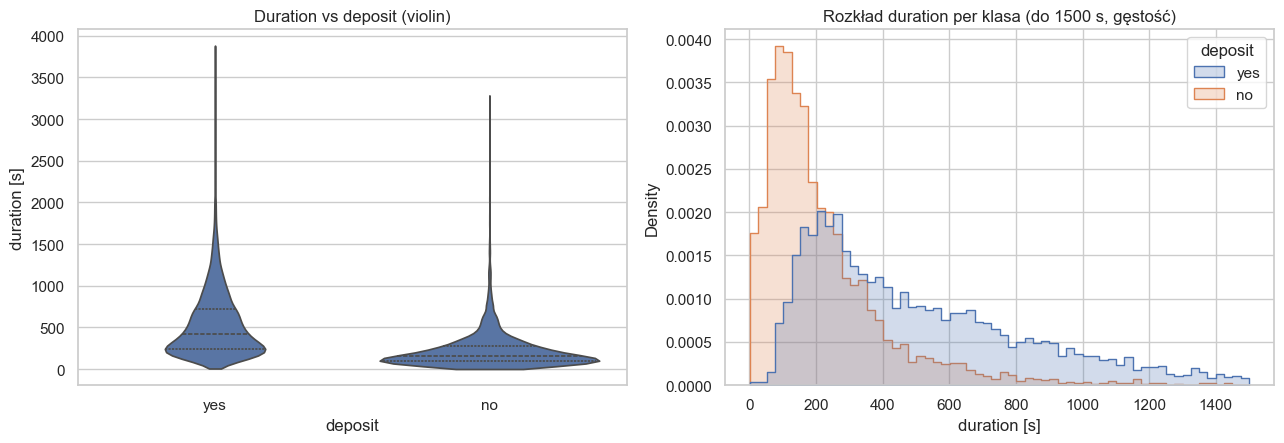

deposit
no     163.0
yes    426.0
Name: duration, dtype: float64

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

sns.violinplot(data=df_bank, x="deposit", y="duration", order=["yes", "no"],
               cut=0, inner="quartile", ax=axes[0])
axes[0].set_title("Duration vs deposit (violin)")
axes[0].set_ylabel("duration [s]")

sns.histplot(data=df_bank[df_bank["duration"] <= 1500], x="duration",
             hue="deposit", hue_order=["yes", "no"], bins=60,
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Rozkład duration per klasa (do 1500 s, gęstość)")
axes[1].set_xlabel("duration [s]")

plt.tight_layout()
plt.show()

df_bank.groupby("deposit")["duration"].median()


## Raportowanie (Excel + narracja) — mini-projekt

Cel: dowieźć artefakt, który można wysłać interesariuszowi.

**Deliverable:**
- `report.xlsx` (obowiązkowo)
- + pliki HTML z Plotly (już masz)
- + (opcjonalnie) `report.html`/`report.pdf` w esparto


### Zadanie 29 (20–30 min)
**Biznes:** Stwórz tabelę podsumowań do arkusza `summary`.

**Technicznie:** przygotuj DataFrame z KPI, np.:
- zakres dat
- liczba stacji
- średnie/mediany PM2.5 i PM10
- top 3 stacje (mediana PM2.5)

**TODO:** zbuduj `df_summary_kpi` (2 kolumny: `metric`, `value`).


In [68]:
df_air

,date_time,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,date,month,hour,season
0,2013-03-01 00:00:00,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi,2013-03-01,3,0,wiosna
1,2013-03-01 01:00:00,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi,2013-03-01,3,1,wiosna
2,2013-03-01 05:00:00,4.0,4.0,9.0,25.0,300.0,78.0,-2.4,1027.5,-21.3,0.0,NW,2.4,Dongsi,2013-03-01,3,5,wiosna
3,2013-03-01 06:00:00,5.0,5.0,10.0,29.0,400.0,67.0,-2.5,1028.2,-20.4,0.0,NW,2.2,Dongsi,2013-03-01,3,6,wiosna
4,2013-03-01 07:00:00,3.0,6.0,12.0,40.0,400.0,52.0,-1.4,1029.5,-20.4,0.0,NNW,3.0,Dongsi,2013-03-01,3,7,wiosna
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95680,2017-02-28 15:00:00,9.0,9.0,2.0,22.0,300.0,91.0,15.4,1013.0,-15.0,0.0,NNW,3.3,Tiantan,2017-02-28,2,15,zima
95681,2017-02-28 16:00:00,10.0,29.0,3.0,21.0,300.0,94.0,14.9,1012.6,-15.4,0.0,NW,2.1,Tiantan,2017-02-28,2,16,zima
95682,2017-02-28 21:00:00,18.0,32.0,4.0,48.0,500.0,48.0,10.8,1014.2,-13.3,0.0,NW,1.1,Tiantan,2017-02-28,2,21,zima
95683,2017-02-28 22:00:00,15.0,42.0,5.0,52.0,600.0,44.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Tiantan,2017-02-28,2,22,zima


In [ ]:
# Zakres dat
date_start = df_air['date'].min()
date_end = df_air['date'].max()

# Liczba stacji
n_stations = df_air['station'].nunique()

# Średnie i mediany PM 2.5 i PM 10
pm25median = df_air['PM2.5'].median()
pm25mean = df_air['PM2.5'].mean()

pm10median = df_air['PM10'].median()
pm10mean = df_air['PM10'].mean()

# Mediana na stację
median_station = df_air.groupby('station')['PM2.5'].median()
median_station_str = ", ".join([f"{idx} ({val:.1f})" for idx, val in median_station.items()])

df_summary_kpi = pd.DataFrame({
    "metric": [
        'date range',
        'number of stations',
        'PM 2.5 median',
        'PM 2.5 mean',
        'PM 10 median',
        'PM 10 mean',
        'Median PM 2.5 per station'
    ],
    "value": [
        f"{date_start} - {date_end}",
        n_stations,
        pm25median,
        pm25mean,
        pm10median,
        pm10mean,
        median_station
    ]
})
df_summary_kpi


,metric,value
0,date range,2013-03-01 - 2017-02-28
1,number of stations,3
2,PM 2.5 median,59.0
3,PM 2.5 mean,83.477884
4,PM 10 median,90.0
5,PM 10 mean,111.899959
6,Median PM 2.5 per station,station Dongsi 60.0 Gucheng 59.0 Tianta...


### Zadanie 30 (30–45 min)
**Biznes:** Wygeneruj `report.xlsx` z 2 arkuszami i prostym formatowaniem.

**Technicznie:** `pd.ExcelWriter(engine='xlsxwriter')`, formaty, freeze panes.

**TODO:**
- Arkusz `summary`: `df_summary_kpi` + (opcjonalnie) wstaw obrazek wykresu PNG.

Podpowiedź: możesz zapisać wykres Matplotlib jako PNG (`savefig`) i wstawić przez `worksheet.insert_image`.


In [80]:
import xlsxwriter

Zapisano report.xlsx


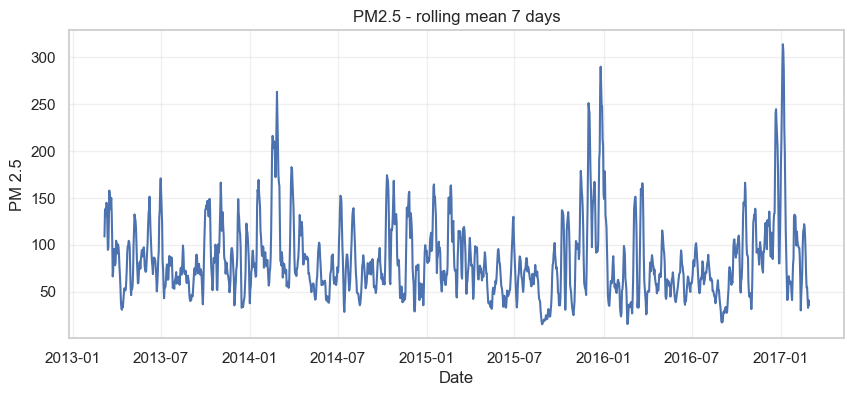

In [81]:
# 1) przygotuj tabele szczegółowe
df_monthly = df_air.groupby('month', as_index=False).agg(pm25median=('PM2.5', 'median')).sort_values('month')

# 2) zapisz jeden wykres do PNG (opcjonalnie)
fig, ax = plt.subplots()
ax.plot(df_daily['date'], df_daily['pm25_roll7'])
ax.set_title('PM2.5 - rolling mean 7 days')
ax.set_xlabel('Date')
ax.set_ylabel('PM 2.5')
ax.grid(True, alpha=0.3)

fig.savefig("chart_pm25_rolling_7days.png", dpi=150, bbox_inches="tight")

# 3) wygeneruj Excel
with pd.ExcelWriter("report.xlsx", engine="xlsxwriter") as writer:
    df_summary_kpi.to_excel(writer, sheet_name="summary", index=False)
    df_monthly.to_excel(writer, sheet_name="details", index=False)
 
    workbook = writer.book
    ws_sum = writer.sheets["summary"]
    ws_det = writer.sheets["details"]

    # format nagłówka
    fmt_header = workbook.add_format({"bold": True, "bg_color": "#EEEEEE"})
    ws_sum.set_row(0, None, fmt_header)
    ws_det.set_row(0, None, fmt_header)

    # freeze panes
    ws_sum.freeze_panes(1, 0)
    ws_det.freeze_panes(1, 0)

    # szerokości kolumn (przykład)
    ws_sum.set_column(0, 0, 24)
    ws_sum.set_column(1, 1, 28)

    # opcjonalnie wstaw obraz
    ws_sum.insert_image("D2", "chart_pm25_rolling_7days.png")

print("Zapisano report.xlsx")


### Bonus (dla chętnych): esparto / folium
- Jeśli masz czas: spróbuj wygenerować prosty raport HTML w esparto (sekcje + obrazy wykresów).
- Jeśli masz lokalizacje (lub je dodasz): zrób mapę w folium i zapisz do HTML.

W tym bloku bonus jest **opcjonalny** — Excel + HTML z Plotly wystarczy jako „produkcyjny” rezultat.
